# Dibujar para hablar
Clasificación de dibujos a mano alzada para que personas que perdieron el habla (afasia tras un ACV, pacientes intubados) comuniquen necesidades básicas: la red reconoce el dibujo y lo traduce a una frase.

| Dibujo | Frase |
|---|---|
| vaso | Tengo sed |
| inodoro | Necesito ir al baño |
| cama | Quiero descansar |
| jeringa | Necesito mi medicina |
| celular | Quiero hablar con mi familia |

In [1]:
import os
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

keras.utils.set_random_seed(42)

## 1. Datos
`X.npy` y `y.npy` se generan con la ruta `/prepare` de la app (dibujos recortados, centrados y llevados a 64×64). Se usaron 530 dibujos por categoría para el dataset.


In [2]:
REPO = "https://raw.githubusercontent.com/SL7u777/PC2Grafica/main/"
for f in ["X.npy", "y.npy"]:
    if not os.path.exists(f):
        urllib.request.urlretrieve(REPO + f, f)

X = np.load("X.npy")
y = np.load("y.npy")
clases = np.unique(y)
print("Imágenes:", X.shape)
print(" | ".join(f"{c}: {(y == c).sum()}" for c in clases))

Imágenes: (2650, 64, 64)
cama: 530 | celular: 530 | inodoro: 530 | jeringa: 530 | vaso: 530


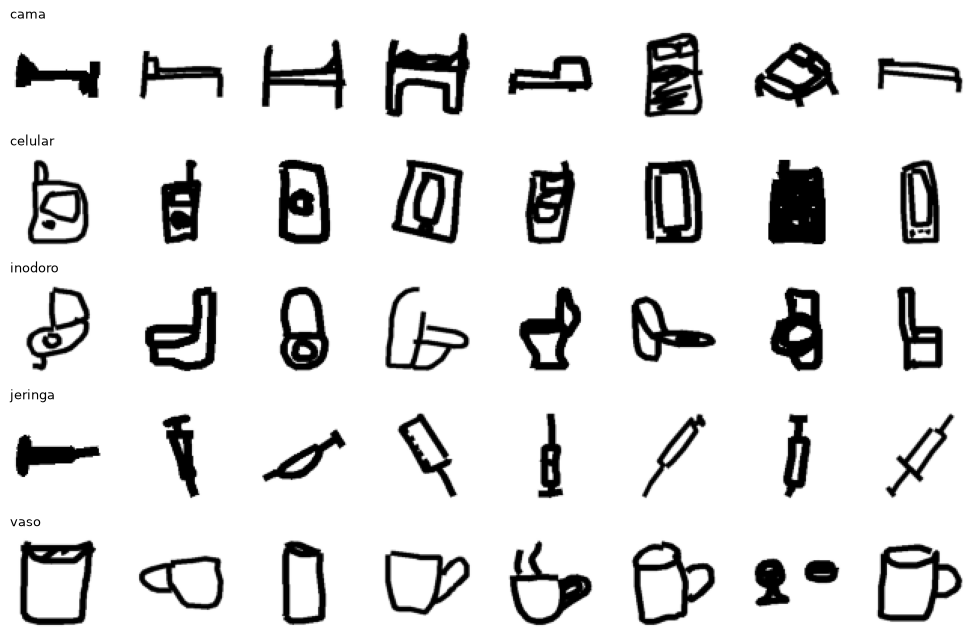

In [3]:
fig, ax = plt.subplots(len(clases), 8, figsize=(10, 6.5))
for i, c in enumerate(clases):
    for j, k in enumerate(np.where(y == c)[0][:8]):
        ax[i, j].imshow(X[k], cmap="gray_r")
        ax[i, j].axis("off")
    ax[i, 0].set_title(c, loc="left", fontsize=9)
plt.tight_layout()
plt.show()

## 2. Preparación
Se escala a [0, 1] y se divide de forma estratificada: 70% entrenamiento, 15% validación y 15% prueba.

In [4]:
X = X.astype("float32")[..., None] / 255.0
y_num = np.searchsorted(clases, y)

X_train, X_tmp, y_train, y_tmp = train_test_split(X, y_num, test_size=0.3, stratify=y_num, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print(f"Entrenamiento: {len(X_train)} | Validación: {len(X_val)} | Prueba: {len(X_test)}")

Entrenamiento: 1855 | Validación: 397 | Prueba: 398


## 3. Red neuronal
CNN con tres bloques convolucionales. El aumento de datos (rotación, zoom, desplazamiento y volteo horizontal) simula la variedad de trazos de distintas personas y solo actúa durante el entrenamiento.

In [5]:
aumento = keras.Sequential([
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomFlip("horizontal"),
], name="aumento")

modelo = keras.Sequential([
    layers.Input((64, 64, 1)),
    aumento,
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dense(len(clases), activation="softmax"),
])
modelo.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento (Sequential)            │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,021 (4.36 MB)

 Trainable params: 1,142,021 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

## 4. Entrenamiento
`EarlyStopping` detiene el entrenamiento cuando la pérdida de validación deja de mejorar y recupera los mejores pesos.

In [6]:
parada = keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
historial = modelo.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=100,
                       batch_size=32, callbacks=[parada], verbose=0)

h = historial.history
mejor = int(np.argmin(h["val_loss"]))
print(f"Épocas: {len(h['loss'])} | Mejor época: {mejor + 1} | val_accuracy: {h['val_accuracy'][mejor]:.3f}")

Épocas: 39 | Mejor época: 31 | val_accuracy: 0.940


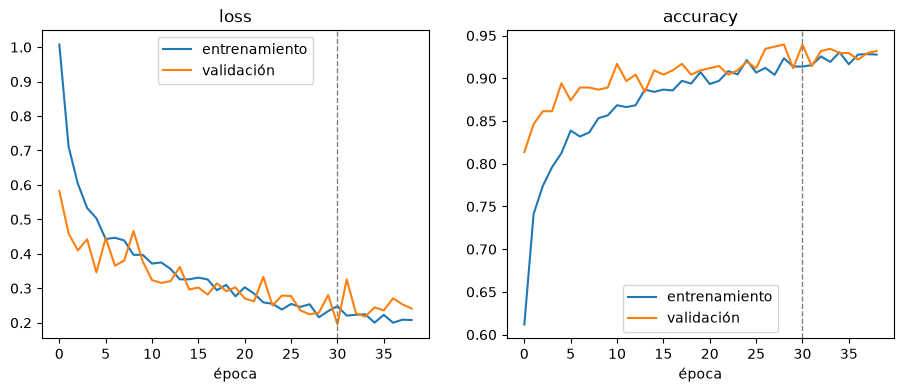

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for i, m in enumerate(["loss", "accuracy"]):
    ax[i].plot(h[m], label="entrenamiento")
    ax[i].plot(h["val_" + m], label="validación")
    ax[i].axvline(mejor, color="gray", ls="--", lw=1)
    ax[i].set_title(m)
    ax[i].set_xlabel("época")
    ax[i].legend()
plt.show()

## 5. Métricas en el conjunto de prueba
Se evalúa con dibujos que la red no vio durante el entrenamiento. **Precision**: de los dibujos que la red asignó a una clase, cuántos eran de esa clase. **Recall**: de los dibujos de una clase, cuántos reconoció. **F1**: promedio armónico de ambas. La matriz de confusión muestra qué clases se confunden entre sí.

In [8]:
prob = modelo.predict(X_test, verbose=0)
y_pred = prob.argmax(axis=1)
print(classification_report(y_test, y_pred, target_names=clases, digits=3))

              precision    recall  f1-score   support

        cama      0.872     0.938     0.904        80
     celular      0.905     0.962     0.933        79
     inodoro      0.894     0.950     0.921        80
     jeringa      0.986     0.875     0.927        80
        vaso      0.917     0.835     0.874        79

    accuracy                          0.912       398
   macro avg      0.915     0.912     0.912       398
weighted avg      0.915     0.912     0.912       398



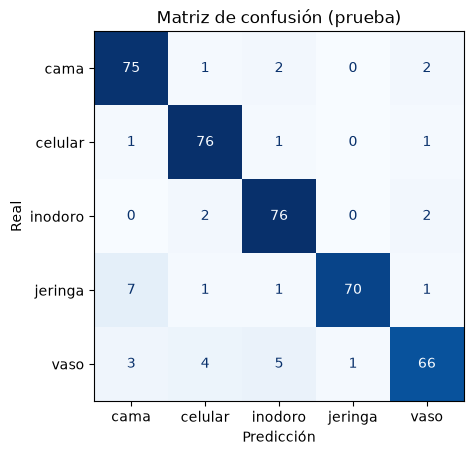

In [9]:
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=clases).plot(cmap="Blues", colorbar=False)
plt.title("Matriz de confusión (prueba)")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.show()

Errores: 35 de 398


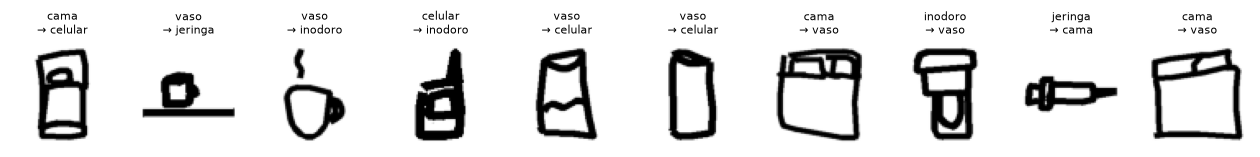

In [10]:
errores = np.where(y_pred != y_test)[0]
print(f"Errores: {len(errores)} de {len(y_test)}")
n = min(len(errores), 10)
if n:
    fig, ax = plt.subplots(1, n, figsize=(1.6 * n, 2.2))
    for a, i in zip(np.atleast_1d(ax), errores[:n]):
        a.imshow(X_test[i, :, :, 0], cmap="gray_r")
        a.set_title(f"{clases[y_test[i]]}\n→ {clases[y_pred[i]]}", fontsize=8)
        a.axis("off")
    plt.show()

## 6. Del dibujo a la frase

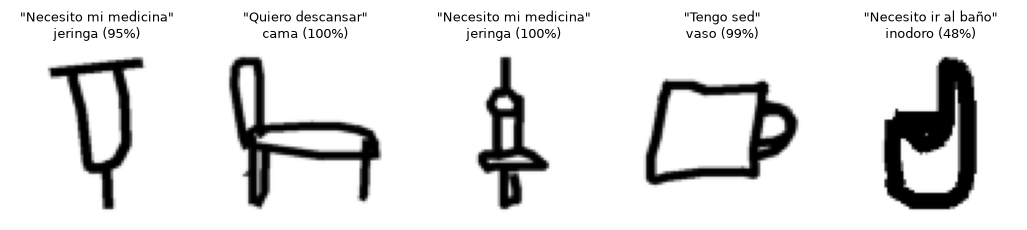

In [11]:
FRASES = {"vaso": "Tengo sed", "inodoro": "Necesito ir al baño", "cama": "Quiero descansar",
          "jeringa": "Necesito mi medicina", "celular": "Quiero hablar con mi familia"}

muestra = np.random.default_rng(1).choice(len(X_test), 5, replace=False)
fig, ax = plt.subplots(1, 5, figsize=(13, 3))
for a, i in zip(ax, muestra):
    c = clases[y_pred[i]]
    a.imshow(X_test[i, :, :, 0], cmap="gray_r")
    a.set_title(f'"{FRASES[c]}"\n{c} ({prob[i].max():.0%})', fontsize=9)
    a.axis("off")
plt.show()

In [12]:
modelo.save("modelo.keras")

## 7. Demo: clasificar un dibujo de la app
Se elige cualquier imagen de `datos/` (por ejemplo, una dibujada en la app durante la exposición) y el modelo ya entrenado la clasifica, sin volver a entrenar. Pasa por el mismo preprocesamiento que `/prepare`. Si la imagen no está en el entorno (Colab), se descarga del repositorio.

In [13]:
from PIL import Image
from skimage.transform import resize


def normalizar(img, tam=64):
    ys, xs = np.nonzero(img)
    img = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    lado = int(max(img.shape) * 1.15)
    cuadro = np.zeros((lado, lado), dtype=np.uint8)
    y0, x0 = (lado - img.shape[0]) // 2, (lado - img.shape[1]) // 2
    cuadro[y0:y0 + img.shape[0], x0:x0 + img.shape[1]] = img
    return resize(cuadro, (tam, tam), anti_aliasing=True).astype("float32")


def clasificar_archivo(ruta):
    if not os.path.exists(ruta):
        os.makedirs(os.path.dirname(ruta), exist_ok=True)
        urllib.request.urlretrieve(REPO + ruta, ruta)
    alfa = np.array(Image.open(ruta))[:, :, 3]
    p = modelo.predict(normalizar(alfa)[None, ..., None], verbose=0)[0]
    c = clases[p.argmax()]
    fig, ax = plt.subplots(1, 2, figsize=(9, 3), gridspec_kw={"width_ratios": [1, 1.6]})
    ax[0].imshow(alfa, cmap="gray_r")
    ax[0].set_title(f'"{FRASES[c]}"')
    ax[0].axis("off")
    ax[1].barh(clases, p, color=["tab:blue" if k == c else "lightgray" for k in clases])
    ax[1].set_xlim(0, 1)
    ax[1].set_title(f"{os.path.basename(ruta)} → {c} ({p.max():.0%})")
    plt.tight_layout()
    plt.show()

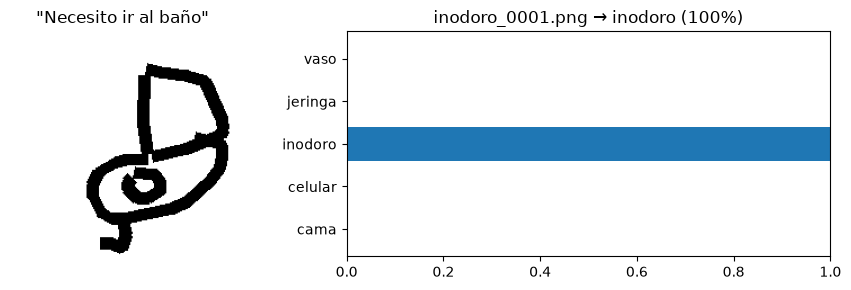

In [14]:
clasificar_archivo("datos/inodoro/inodoro_0001.png")